#Лабораторна робота 1
###Варінат 2: Impact of AI on Students
Виконала: Слота Аліна

In [1]:
import pandas as pd
import numpy as np
import sqlite3

# Завантаження даних з CSV файлу
data = pd.read_csv('ai_student_impact_dataset.csv')

# Додавання timestamp
start = pd.Timestamp("2025-01-01")
end = pd.Timestamp("2025-12-31 23:59:59")
data['timestamp'] = pd.to_datetime(np.random.randint(start.value // 10**9, end.value // 10**9, len(data)), unit='s')

# Підключення до SQLite бази даних
conn = sqlite3.connect('students.db')
data.to_sql('student_impact', conn, if_exists='replace', index=False)
conn.close()

In [2]:
data.describe()

,Student_ID,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,timestamp
count,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000
mean,125000.500000,3.146102,8.427752,2.80026,11.209271,3.505360,4.270760,3.349299,75.798125,2025-07-03 00:16:40
min,100001.000000,1.183000,0.000000,1.00000,1.000000,1.000000,1.000000,1.000000,10.780000,2025-01-01 00:18:31
25%,112500.750000,2.834000,2.390000,2.00000,7.560000,2.000000,3.000000,3.023750,66.820000,2025-04-02 16:25:49
50%,125000.500000,3.210000,5.800000,3.00000,11.180000,3.000000,4.000000,3.421000,76.000000,2025-07-03 22:32:18
75%,137500.250000,3.521000,11.720000,4.00000,14.710000,5.000000,6.000000,3.749000,85.190000,2025-10-01 16:45:32
max,150000.000000,3.998000,40.000000,5.00000,35.860000,10.000000,10.000000,4.000000,100.000000,2025-12-31 23:54:05
std,14433.901067,0.478854,8.269490,1.18802,5.156426,1.820812,2.144066,0.495673,13.281626,NaN


Короткий опис структури таблиці

In [3]:
print(data.shape) # Розмір таблиці
print(data.dtypes) # Типи даних
print(data.head()) # Перші 5 рядків

(50000, 17)
Student_ID                            int64
Major_Category                          str
Year_of_Study                           str
Pre_Semester_GPA                    float64
Weekly_GenAI_Hours                  float64
Primary_Use_Case                        str
Prompt_Engineering_Skill                str
Tool_Diversity                        int64
Paid_Subscription                      bool
Traditional_Study_Hours             float64
Perceived_AI_Dependency               int64
Institutional_Policy                    str
Anxiety_Level_During_Exams            int64
Post_Semester_GPA                   float64
Skill_Retention_Score               float64
Burnout_Risk_Level                      str
timestamp                     datetime64[s]
dtype: object
   Student_ID Major_Category Year_of_Study  Pre_Semester_GPA  \
0      100001     Humanities        Senior             2.418   
1      100002        Medical        Junior             3.821   
2      100003       Business      

Таблиця містить 50 000 записів і 17 полів. Типи даних: числові показники збережено як int64/float64; категоріальні - str, a Paid_Subscription як логічне (bool), timestamp має тип datetime64.

##Звіт про дослідження даних (EDA):

Початкова гіпотеза: інтенсивність використання GenAI, рівень залежності від AI та рівень тривожності пов'язані з цільовою змінною (Burnout_Risk_Level). Передбачається, що студенти з високим ризиком вигорання матимуть вищі значення показників Weekly_GenAI_Hours, Perceived_AI_Dependency, Anxiety_Level_During_Exams та нижчу успішність Post_Semester_GPA.

Пропущені значення ознак:

In [4]:
missing_values = data.isnull().sum()
missing_percentage = (missing_values / len(data)) * 100

missing_report = pd.DataFrame({'Кількість пропусків': missing_values, 'Відсоток, %': missing_percentage})
print(missing_report)


                            Кількість пропусків  Відсоток, %
Student_ID                                    0          0.0
Major_Category                                0          0.0
Year_of_Study                                 0          0.0
Pre_Semester_GPA                              0          0.0
Weekly_GenAI_Hours                            0          0.0
Primary_Use_Case                              0          0.0
Prompt_Engineering_Skill                      0          0.0
Tool_Diversity                                0          0.0
Paid_Subscription                             0          0.0
Traditional_Study_Hours                       0          0.0
Perceived_AI_Dependency                       0          0.0
Institutional_Policy                          0          0.0
Anxiety_Level_During_Exams                    0          0.0
Post_Semester_GPA                             0          0.0
Skill_Retention_Score                         0          0.0
Burnout_Risk_Level      

Результат: відсутні пропуски у всіх 17 колонках.

Помилки даних:

In [5]:
categorical_cols = ['Major_Category', 'Year_of_Study', 'Primary_Use_Case',
                     'Prompt_Engineering_Skill', 'Institutional_Policy',
                     'Burnout_Risk_Level']

for col in categorical_cols:
    print(f"\n{col}")
    print(sorted(data[col].unique()))


Major_Category
['Arts', 'Business', 'Humanities', 'Medical', 'STEM']

Year_of_Study
['Freshman', 'Graduate', 'Junior', 'Senior', 'Sophomore']

Primary_Use_Case
['Copywriting/Drafting', 'Debugging/Troubleshooting', 'Direct_Answer_Generation', 'Ideation', 'Summarizing_Reading']

Prompt_Engineering_Skill
['Advanced', 'Beginner', 'Intermediate']

Institutional_Policy
['Actively_Encouraged', 'Allowed_With_Citation', 'Strict_Ban']

Burnout_Risk_Level
['High', 'Low', 'Medium']


Результат: розбіжностей немає.

Типи даних ознак:

In [6]:
print(data.dtypes)
print("\n")
print(data.dtypes.value_counts())

Student_ID                            int64
Major_Category                          str
Year_of_Study                           str
Pre_Semester_GPA                    float64
Weekly_GenAI_Hours                  float64
Primary_Use_Case                        str
Prompt_Engineering_Skill                str
Tool_Diversity                        int64
Paid_Subscription                      bool
Traditional_Study_Hours             float64
Perceived_AI_Dependency               int64
Institutional_Policy                    str
Anxiety_Level_During_Exams            int64
Post_Semester_GPA                   float64
Skill_Retention_Score               float64
Burnout_Risk_Level                      str
timestamp                     datetime64[s]
dtype: object


str              6
float64          5
int64            4
bool             1
datetime64[s]    1
Name: count, dtype: int64


Результат: Числові колонки - 9, категоріальні - 6, булеві - 1, дата - 1.

Розподіл ключових ознак:

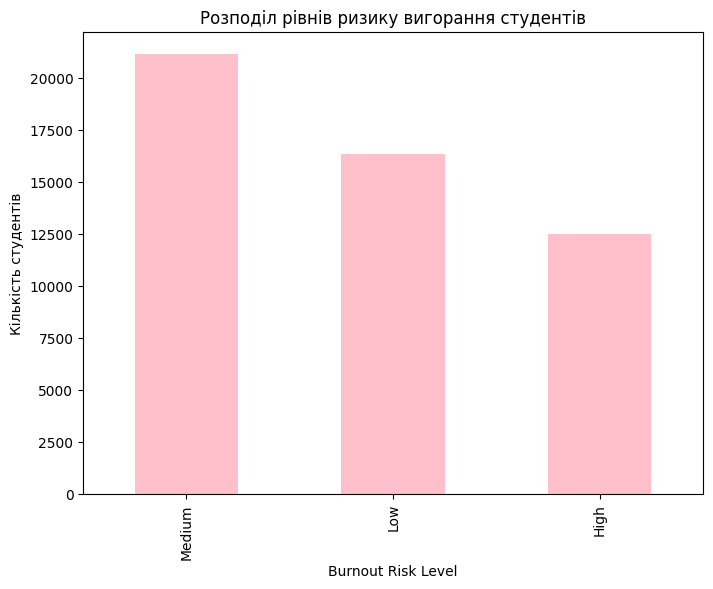

Burnout_Risk_Level
Medium    42.288
Low       32.738
High      24.974
Name: proportion, dtype: float64


In [7]:
import matplotlib.pyplot as plt

# Розподіл цільової змінної
plt.figure(figsize=(8, 6))
data['Burnout_Risk_Level'].value_counts().plot(kind='bar', color=['Pink'])
plt.title('Розподіл рівнів ризику вигорання студентів')
plt.xlabel('Burnout Risk Level')
plt.ylabel('Кількість студентів')
plt.show()

print(data['Burnout_Risk_Level'].value_counts(normalize=True) * 100) # Відсотковий розподіл

Результат: Класи розподілені помірно рівномірно без критичного дисбалансу; переважає клас Medium.

Маштаб значень ознак

In [8]:
numeric_data = data.select_dtypes(include=[np.number])
scale_report = pd.DataFrame({'Мінімум': numeric_data.min(), 
                             'Максимум': numeric_data.max(),
                             'Маштаб': (numeric_data.max() - numeric_data.min())
                             })

print(scale_report)

                               Мінімум    Максимум     Маштаб
Student_ID                  100001.000  150000.000  49999.000
Pre_Semester_GPA                 1.183       3.998      2.815
Weekly_GenAI_Hours               0.000      40.000     40.000
Tool_Diversity                   1.000       5.000      4.000
Traditional_Study_Hours          1.000      35.860     34.860
Perceived_AI_Dependency          1.000      10.000      9.000
Anxiety_Level_During_Exams       1.000      10.000      9.000
Post_Semester_GPA                1.000       4.000      3.000
Skill_Retention_Score           10.780     100.000     89.220


Результат: ознаки мають суттєво різний маштаб значень. Student_ID має маштаб 50 000, оскільки це просто унікальний номер студента, який в подальшому слід виключити з аналізу. Skill_Retention_Score має найбільший реальний розмах - 82.9,
Pre_Semester_GPA та Post_Semester_GPA мають найменший розмах, оскільки це 4 бальна система оцінювання.

Кореляціний аналіз між атрибутами

In [9]:
correlation_matrix = data[numeric_data.columns].corr()

correlation_matrix.style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1).format("{:.2f}")

,Student_ID,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score
Student_ID,1.00,0.00,0.00,-0.00,0.00,0.00,0.01,-0.00,-0.00
Pre_Semester_GPA,0.00,1.00,-0.00,-0.01,-0.00,0.00,-0.00,0.93,0.10
Weekly_GenAI_Hours,0.00,-0.00,1.00,0.01,-0.16,0.67,0.27,-0.02,-0.12
Tool_Diversity,-0.00,-0.01,0.01,1.00,0.00,0.01,0.00,0.03,0.20
Traditional_Study_Hours,0.00,-0.00,-0.16,0.00,1.00,-0.10,-0.04,0.14,0.15
Perceived_AI_Dependency,0.00,0.00,0.67,0.01,-0.10,1.00,0.31,-0.01,-0.08
Anxiety_Level_During_Exams,0.01,-0.00,0.27,0.00,-0.04,0.31,1.00,-0.02,-0.04
Post_Semester_GPA,-0.00,0.93,-0.02,0.03,0.14,-0.01,-0.02,1.00,0.17
Skill_Retention_Score,-0.00,0.10,-0.12,0.20,0.15,-0.08,-0.04,0.17,1.00


                    Weekly_GenAI_Hours  Perceived_AI_Dependency  \
Burnout_Risk_Level                                                
High                         15.214823                 4.641707   
Low                           4.643648                 2.819965   
Medium                        7.349047                 3.364879   

                    Anxiety_Level_During_Exams  
Burnout_Risk_Level                              
High                                  4.889325  
Low                                   3.928462  
Medium                                4.170450  


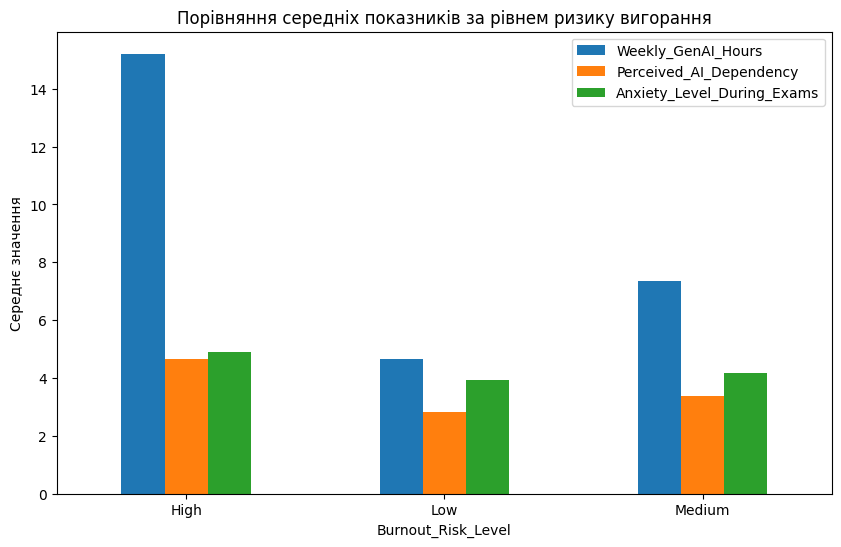

In [10]:
key_features = [
    'Weekly_GenAI_Hours',
    'Perceived_AI_Dependency',
    'Anxiety_Level_During_Exams'
]

group_comparison = data.groupby('Burnout_Risk_Level')[key_features].mean()
print(group_comparison)

group_comparison.plot(kind='bar', figsize=(10,6))
plt.title('Порівняння середніх показників за рівнем ризику вигорання')
plt.ylabel('Середнє значення')
plt.xticks(rotation=0)
plt.show()

Результат: найсильніший кореляціний зв'язок з іншими числовмим ознаками у Post_Semester_GPA та Pre_Semester_GPA (коефіцієнт кореляції - 0,93), а також  Perceived_AI_Dependency і Weekly_GenAI_Hours (коефіцієн кораляції 0.67).

Групування за Burnout_Risk_Level показує, що студенти з групи High мають вищий показник Perceived_AI_Dependency, Anxiety_Level_During_Exams в порівнянні з групою Low, а також значно вище значення Weekly_GenAI_Hours, що підтверджує початкову гіпотезу. 

Виявлення аутлаєрів (аномальних значень)

       Weekly_GenAI_Hours  Perceived_AI_Dependency  Anxiety_Level_During_Exams
count            50000.00                 50000.00                    50000.00
mean                 8.43                     3.51                        4.27
std                  8.27                     1.82                        2.14
min                  0.00                     1.00                        1.00
25%                  2.39                     2.00                        3.00
50%                  5.80                     3.00                        4.00
75%                 11.72                     5.00                        6.00
max                 40.00                    10.00                       10.00


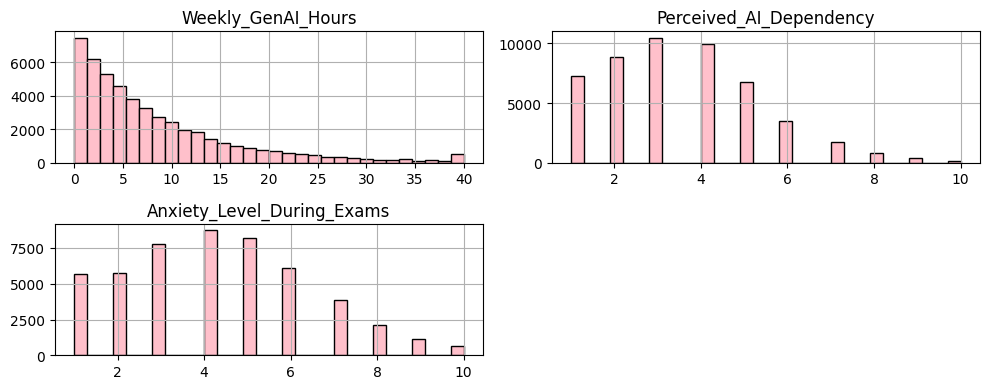

In [11]:
print(data[key_features].describe().round(2))

data[key_features].hist(figsize=(10, 4), bins=30,color='pink', edgecolor='black')
plt.tight_layout()
plt.show()

Результат: 
Weekly_GenAI_Hours: правостороння асиметрія (спад), присутній стрибок на позначці 40 годин, що значає штучне обмеження шкали.

Perceived_AI_Dependency: зміщений ліворуч дискретний розподіл, в більшості залежність від AI оцінена як невисока.

Anxiety_Level_During_Exams: розподіл блтизький до умовно нормального, але з легким скосом вправо, більшість студентів відчуває середній рівень тривоги під час іспитів

Отже, усі три показники мають несеметричний розподіл різного типу.

Прості агрегації

In [12]:
# Середній бал до і після семестру
agg_by_major = data.groupby('Major_Category')[['Pre_Semester_GPA', 'Post_Semester_GPA']].mean()
print(agg_by_major)

print('\n')
# Середня кількість годин використання AI 
agg_by_year = data.groupby('Year_of_Study')['Weekly_GenAI_Hours'].mean().sort_values()
print(agg_by_year)

                Pre_Semester_GPA  Post_Semester_GPA
Major_Category                                     
Arts                    3.146786           3.343688
Business                3.141760           3.336085
Humanities              3.147850           3.345825
Medical                 3.151769           3.353168
STEM                    3.145852           3.363154


Year_of_Study
Junior       8.376325
Graduate     8.406052
Sophomore    8.446249
Freshman     8.446962
Senior       8.459251
Name: Weekly_GenAI_Hours, dtype: float64


Результат: середній GPA зростає для всіх напрямів - отже, розподіл академінчої успішності рівномірний для всіх галузей. Щодо використання ШІ, то усі студенти витрачають приблизно однаковий час.

Статистичний аналіз (перевірка значущості зв'язку)

In [13]:
stats_by_group = data.groupby('Burnout_Risk_Level')['Weekly_GenAI_Hours'].agg(
    ['mean', 'median', 'std', 'min', 'max']
)
print(stats_by_group)

# Коефіцієнт кореляції
correlation = data['Weekly_GenAI_Hours'].corr(data['Anxiety_Level_During_Exams'])
print(f"\nКоефіцієнт кореляції: {correlation:.3f}")

                         mean  median        std  min   max
Burnout_Risk_Level                                         
High                15.214823  13.250  10.613842  0.0  40.0
Low                  4.643648   3.410   4.265532  0.0  38.0
Medium               7.349047   5.625   6.453460  0.0  40.0

Коефіцієнт кореляції: 0.269


Результат: середнє значення Weekly_GenAI_Hours у групі High значно вище, ніж у групі Low, а стандартне відхилення показує великий розкид значень у середині групи; коефіцієнт кореляції показує слабкий позитивний зв'язок між Weekly_GenAI_Hours та Anxiety_Level_During_Exams

##Звіт про якість даних
Типи проблем якості даних:
Відсутні дані: у таблиці немає пропущених значень. Усі клітинки заповнені, а прихованих пропусків у вигляді нулів, знаків питання чи інших спеціальних символів не знайдено.

Помилки в тексті та одруківки: у текстових колонках немає зайвих пробілів чи плутанини з великими і малими літерами. Усі слова та назви категорій написані однаково й без помилок.

Похибки вимірювання: усі числові дані в межах норми. Середній бал оцінок не виходить за допустимі межі від 0 до 4, показники часу не є від'ємними, а бали опитувань чітко відповідають своїм шкалам. Аномалій чи неможливих чисел не виявлено.

Правильність кодування: усі категорії записані за єдиним стандартом. Немає дублювання синонімів, коли одне й те саме значення записано по-різному.

Відповідність назв і змісту: назви всіх стовпців точно описують їхнє наповнення. Там, де мають бути години використання, записані саме числа, а там, де вказано рівень ризику — відповідний текст. Плутанини між стовпцями немає.